# 08 · Player profiles, similarity and role clustering

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import config as C
pd.set_option("display.width", 160, "display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True,
                     "grid.alpha": .25, "figure.dpi": 110})
E = C.PROCESSED_DIR / "events"; D = C.DERIVED_DIR
rd  = lambda n: pd.read_parquet(D / f"{n}.parquet")
rev = lambda n: pd.read_parquet(E / f"{n}.parquet")
print("project:", C.PROJECT_ROOT.name)

project: basketball-intelligence


In [2]:
gl = rd("player_game_profile")
print(f"{len(gl)} players with a tracked profile")
gl[gl.minutes_tracked >= 8].nlargest(12, "points")[["player_name","team_name","games",
  "minutes_tracked","points","fga","fg_pct","xfg","shot_value_added","drives","drive_ppd",
  "picks_used","pick_ppp","distance_per_min","p95_speed"]].round(3)

208 players with a tracked profile


,player_name,team_name,games,minutes_tracked,points,fga,fg_pct,xfg,shot_value_added,drives,drive_ppd,picks_used,pick_ppp,distance_per_min,p95_speed
80,Francisco Alonso,Leche Rio Breogan,2.0,63.172,34.0,22.0,0.591,0.418,9.607,11.0,0.727,15.0,0.267,316.614,13.571
74,Santiago Yusta,Casademont Zaragoza,2.0,70.769,32.0,23.0,0.609,0.460,5.193,13.0,0.615,8.0,0.625,325.128,14.231
81,DeWayne Russell,Leche Rio Breogan,2.0,56.035,31.0,29.0,0.483,0.449,1.287,27.0,0.704,73.0,0.863,334.484,13.336
126,Justin Jaworski,Bilbao Basket,1.0,45.381,30.0,20.0,0.600,0.484,5.052,7.0,0.714,13.0,0.462,322.657,13.595
3,Kassius Robertson,Dreamland Gran Canaria,2.0,57.593,25.0,15.0,0.600,0.436,8.058,15.0,0.133,27.0,0.407,330.289,13.669
161,Jean Claudio Montero,Valencia BC,1.0,34.315,23.0,17.0,0.529,0.399,5.139,11.0,0.455,27.0,0.741,298.740,13.492
185,Marcelinho Huertas,Lenovo Tenerife,1.0,32.922,23.0,17.0,0.647,0.447,6.672,12.0,1.000,58.0,0.931,332.658,13.119
192,Kevin Punter,BC Barcelona,1.0,26.390,22.0,14.0,0.643,0.369,10.145,6.0,1.333,19.0,0.947,324.205,12.969
16,Timothe Luwawu-Cabarrot,Bitci Baskonia,1.0,31.069,20.0,14.0,0.643,0.486,3.811,10.0,0.800,5.0,0.400,288.425,13.411
119,Aaron Best,BC MoraBanc Andorra,1.0,34.855,20.0,14.0,0.571,0.440,4.784,9.0,0.889,11.0,1.091,354.348,14.179


## Style space: PCA on the season aggregates

In [3]:
from src.models.similarity import StyleSpace
style = rd("season_style")
ss = StyleSpace(style)
print(f"{len(style)} player-team seasons, {len(ss.features)} features -> "
      f"{ss.n_components} components, {ss.explained:.1%} variance")
load = pd.DataFrame({"feature": ss.features,
                     **{f"pc{i+1}": ss.pca.components_[i] for i in range(3)}})
load.reindex(load.pc1.abs().sort_values(ascending=False).index).round(3)

233 player-team seasons, 21 features -> 9 components, 87.6% variance


,feature,pc1,pc2,pc3
0,rim_attempt_rate,0.326,-0.199,0.126
20,pick_role_ratio,-0.322,-0.144,0.109
17,screener_picks_per_game,0.304,-0.104,0.012
6,avg_shot_distance,-0.304,0.280,-0.087
16,handler_picks_per_game,-0.288,-0.252,0.124
10,drives_per_game,-0.278,-0.298,0.034
2,three_attempt_rate,-0.268,0.315,-0.057
4,cns_share,0.255,0.345,-0.015
7,assisted_share,0.253,0.323,-0.066
9,ft_rate,0.210,-0.280,0.097


## Choosing k — and finding that there is no good k

 k   inertia  silhouette
 3 2440.4058      0.2663
 4 2240.6699      0.2391
 5 2111.7192      0.1627
 6 1991.4377      0.1702
 7 1879.3537      0.1878
 8 1812.4126      0.1634
 9 1720.1355      0.1669


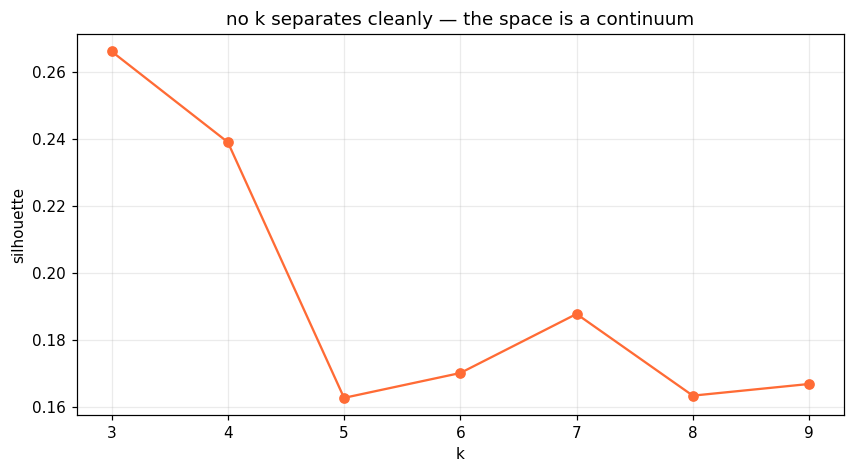

In [4]:
kt = ss.choose_k(); print(kt.round(4).to_string(index=False))
plt.plot(kt.k, kt.silhouette, "o-", color="#FF6B35")
plt.xlabel("k"); plt.ylabel("silhouette"); plt.title("no k separates cleanly — the space is a continuum")
plt.show()

In [5]:
ss.cluster(int(kt.loc[kt.silhouette.idxmax(),"k"]))
print(ss.describe_clusters().to_string(index=False))
print()
print(ss.representatives().round(2).to_string(index=False))

 cluster  n                                                                                                           high                                                                                                    low
       0 65                  screener_picks_per_game (+1.30), rim_attempt_rate (+1.26), ft_rate (+0.87), cns_share (+0.61)  avg_shot_distance (-1.28), three_attempt_rate (-1.25), pick_role_ratio (-1.08), corner3_share (-0.82)
       1 74                   corner3_share (+1.03), three_attempt_rate (+0.76), assisted_share (+0.72), cns_share (+0.71) drives_per_game (-0.60), ft_rate (-0.59), handler_picks_per_game (-0.56), shot_volume_per_game (-0.51)
       2 94 drives_per_game (+1.00), pick_role_ratio (+0.99), handler_picks_per_game (+0.95), shot_volume_per_game (+0.69)   cns_share (-0.98), assisted_share (-0.98), screener_picks_per_game (-0.60), rim_attempt_rate (-0.49)

 cluster       player_name              team_name  dist_to_centroid
       0    Juan Fernandez 

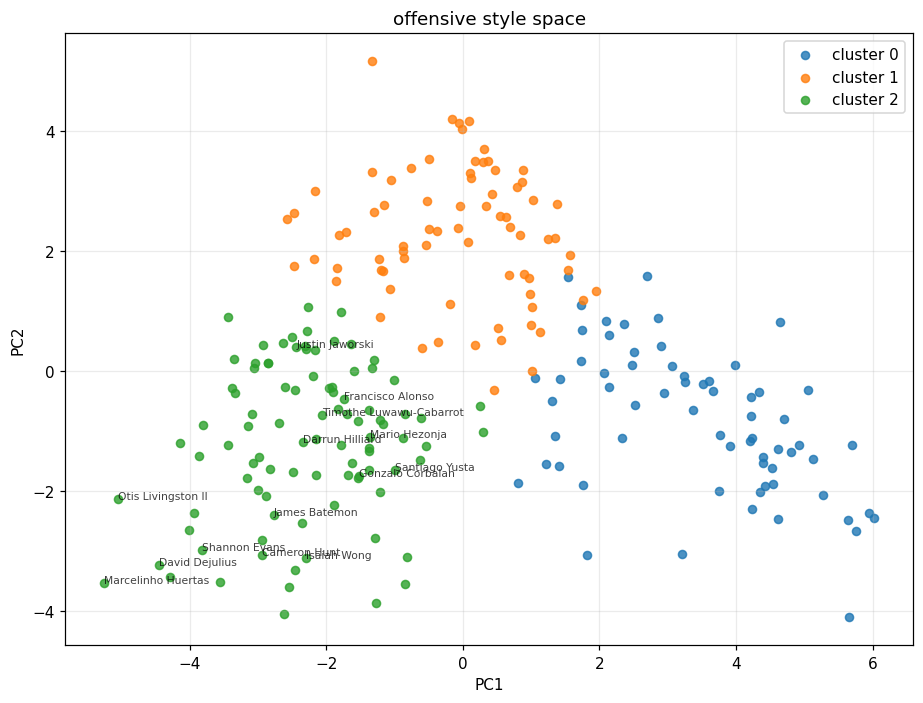

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))
for c_ in sorted(set(ss.labels)):
    sel = ss.labels == c_
    ax.scatter(ss.P[sel,0], ss.P[sel,1], s=28, alpha=.8, label=f"cluster {c_}")
for i in np.argsort(-style.attempts.to_numpy())[:14]:
    ax.annotate(style.player_name.iloc[i], (ss.P[i,0], ss.P[i,1]), fontsize=7, alpha=.75)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(); ax.set_title("offensive style space")
plt.tight_layout(); plt.show()

## Similarity

In [7]:
i = int(style.index[style.player_name.str.contains("Rubio", na=False)][0]) \
    if style.player_name.str.contains("Rubio", na=False).any() else int(style.attempts.idxmax())
print("most similar to", style.loc[i,"player_name"], "—", style.loc[i,"team_name"])
ss.most_similar(i, 10).round(3)

most similar to Ricky Rubio — Club Joventut Badalona


,player_name,team_name,games_played,similarity,closest_on
0,Hugo Benitez,BAXI Manresa,13,0.959,"handler_assist_rate, pick_role_ratio, end_type..."
1,DeWayne Russell,Leche Rio Breogan,31,0.955,"rim_attempt_rate, blowby_rate, pick_role_ratio"
2,Otis Livingston II,Basquet Girona,34,0.942,"handler_pass_rate, handler_assist_rate, rim_at..."
3,David Dejulius,CB UCAM Murcia,31,0.940,"screener_picks_per_game, pick_role_ratio, avg_..."
4,Lluis Costa,Coviran Granada,28,0.933,"rim_attempt_rate, pick_role_ratio, screener_pi..."
5,Jaime Fernandez Bernabe,Lenovo Tenerife,31,0.906,"avg_shot_distance, blowby_rate, end_type_kicko..."
6,Kendrick Perry,Malaga,33,0.903,"assists_rate, rim_attempt_rate, contested_share"
7,Caleb Agada,ICG Forca Lleida,33,0.901,"blowby_rate, pick_role_ratio, screener_picks_p..."
8,Dominik Mavra,Leche Rio Breogan,34,0.901,"blowby_rate, pick_role_ratio, screener_picks_p..."
9,Marcelinho Huertas,Lenovo Tenerife,27,0.888,"pick_role_ratio, avg_shot_distance, screener_p..."
